In [1]:
%load_ext autoreload
%autoreload 2

In [131]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F

from recover.constants import DATA_DIR

In [ ]:
import rasterio as rio

raster = rio.open(DATA_DIR / 'NTAmericas_efgs_50km.tif')
raster

<open DatasetReader name='/Users/guilherme.barauna/personal/luh2esa/data/NTAmericas_efgs_50km.tif' mode='r'>

In [39]:
luh = pd.read_parquet(DATA_DIR / 'luh_timeseries.parquet')
luh

esa = pd.read_parquet(DATA_DIR / 'esa_timeseries.parquet')
esa

,cell,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water,year
0,11.0,0.000000,0.006113,7.063003e-01,0.0,0.252368,0.000000,0.000245,0.000000,0.0,0.034974,0.0,0.000000,0.000000,0.0,0.000000,1992.0
1,12.0,0.000000,0.020214,6.946248e-01,0.0,0.199595,0.000000,0.063771,0.000000,0.0,0.021795,0.0,0.000000,0.000000,0.0,0.000000,1992.0
2,13.0,0.000000,0.000590,5.325985e-01,0.0,0.382702,0.000000,0.081749,0.000000,0.0,0.002361,0.0,0.000000,0.000000,0.0,0.000000,1992.0
3,188.0,0.000000,0.000000,9.438064e-01,0.0,0.000000,0.000000,0.010905,0.000000,0.0,0.045288,0.0,0.000000,0.000000,0.0,0.000000,1992.0
4,189.0,0.000000,0.007885,5.903125e-01,0.0,0.000128,0.000000,0.008111,0.000000,0.0,0.393563,0.0,0.000000,0.000000,0.0,0.000000,1992.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251467,28012.0,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.002743,0.000000,0.000000,0.0,0.717140,0.0,0.050186,0.000000,0.0,0.229930,2022.0
251468,28187.0,0.000340,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.001019,0.000000,0.0,0.780646,0.0,0.202280,0.000000,0.0,0.015715,2022.0
251469,28188.0,0.016389,0.000264,3.960770e-04,0.0,0.000000,0.000000,0.009044,0.000033,0.0,0.543705,0.0,0.410193,0.000924,0.0,0.019052,2022.0
251470,28189.0,0.025259,0.000000,4.884014e-08,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.786287,0.0,0.188454,0.000000,0.0,0.000000,2022.0


In [55]:
def cell2idx(cell_id: int, rows: int = 157, cols: int = 180):
    j = int(cell_id % cols)
    i = int(cell_id // cols)
    return i, j

print(cell2idx(179.0))

(0, 179)


In [58]:
from recover.visualise import plot_single_band

In [85]:
esa

,cell,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water,year
0,11.0,0.000000,0.006113,7.063003e-01,0.0,0.252368,0.000000,0.000245,0.000000,0.0,0.034974,0.0,0.000000,0.000000,0.0,0.000000,1992.0
1,12.0,0.000000,0.020214,6.946248e-01,0.0,0.199595,0.000000,0.063771,0.000000,0.0,0.021795,0.0,0.000000,0.000000,0.0,0.000000,1992.0
2,13.0,0.000000,0.000590,5.325985e-01,0.0,0.382702,0.000000,0.081749,0.000000,0.0,0.002361,0.0,0.000000,0.000000,0.0,0.000000,1992.0
3,188.0,0.000000,0.000000,9.438064e-01,0.0,0.000000,0.000000,0.010905,0.000000,0.0,0.045288,0.0,0.000000,0.000000,0.0,0.000000,1992.0
4,189.0,0.000000,0.007885,5.903125e-01,0.0,0.000128,0.000000,0.008111,0.000000,0.0,0.393563,0.0,0.000000,0.000000,0.0,0.000000,1992.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251467,28012.0,0.000000,0.000000,0.000000e+00,0.0,0.000000,0.002743,0.000000,0.000000,0.0,0.717140,0.0,0.050186,0.000000,0.0,0.229930,2022.0
251468,28187.0,0.000340,0.000000,0.000000e+00,0.0,0.000000,0.000000,0.001019,0.000000,0.0,0.780646,0.0,0.202280,0.000000,0.0,0.015715,2022.0
251469,28188.0,0.016389,0.000264,3.960770e-04,0.0,0.000000,0.000000,0.009044,0.000033,0.0,0.543705,0.0,0.410193,0.000924,0.0,0.019052,2022.0
251470,28189.0,0.025259,0.000000,4.884014e-08,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.786287,0.0,0.188454,0.000000,0.0,0.000000,2022.0


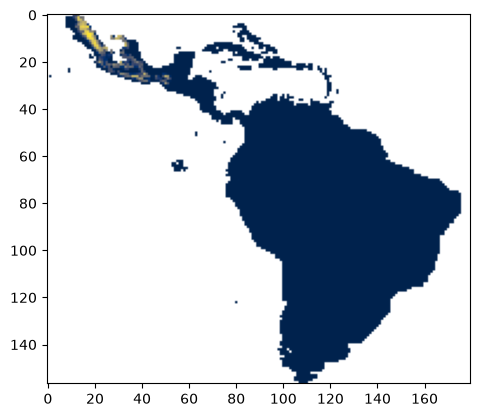

In [86]:
out = np.ones((157, 180)) * 255
for _, row in esa.query('year == 2020').iterrows():
    i, j = cell2idx(row['cell'])
    out[i, j] = row['ESA_Forest_Woodland']
out = np.ma.masked_array(out, out == 255)

plot_single_band(out)

In [84]:
luh.query('year == 2020')

,cell,pastr,primf,primn,range,secdf,secdn,urban,crops,year
397488,11.0,0.0,0.0,0.284850,0.612560,0.0,0.011510,1.052528e-04,7.785953e-02,2020.0
397489,12.0,0.0,0.0,0.288158,0.601748,0.0,0.017829,1.082553e-04,9.215652e-02,2020.0
397490,13.0,0.0,0.0,0.319686,0.539310,0.0,0.034769,1.241659e-04,1.061104e-01,2020.0
397491,188.0,0.0,0.0,0.283061,0.424934,0.0,0.042491,5.853966e-04,2.489294e-01,2020.0
397492,189.0,0.0,0.0,0.295170,0.394828,0.0,0.047838,6.112923e-04,2.615533e-01,2020.0
...,...,...,...,...,...,...,...,...,...,...
405595,28012.0,0.0,0.0,0.000036,0.161139,0.0,0.054762,7.030486e-07,4.155039e-26,2020.0
405596,28187.0,0.0,0.0,0.048448,0.574377,0.0,0.372558,5.228693e-06,0.000000e+00,2020.0
405597,28188.0,0.0,0.0,0.037148,0.594296,0.0,0.356733,9.723607e-06,0.000000e+00,2020.0
405598,28189.0,0.0,0.0,0.141505,0.440526,0.0,0.417956,1.298725e-05,0.000000e+00,2020.0


In [98]:
biome_df = pd.DataFrame(biomes.ravel()).dropna()
biome_df.columns = ['efg']
biome_df['efg'] = biome_df['efg'].astype(int)
biome_df['cell'] = biome_df.index + 1

In [99]:
biome_df

,efg,cell
10,11,11
11,11,12
12,11,13
187,16,188
188,16,189
...,...,...
28011,7,28012
28186,7,28187
28187,7,28188
28188,7,28189


In [112]:
luh_cols = [c for c in luh.columns if c not in ('cell', 'year')]
esa_cols = [c for c in esa.columns if c not in ('cell', 'year')]

luh_cols, esa_cols

(['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops'],
 ['ESA_BareAreas',
  'ESA_Cropland',
  'ESA_Forest_Bl_Dec',
  'ESA_Forest_Bl_Ev',
  'ESA_Forest_Woodland',
  'ESA_ForestMosaic',
  'ESA_Grassland',
  'ESA_GrasslandMosaic',
  'ESA_Mangrove',
  'ESA_Shrubland',
  'ESA_SnowIce',
  'ESA_SparseVegetation',
  'ESA_Urban',
  'ESA_Varzea',
  'ESA_Water'])

In [119]:
luh[luh_cols].sum(axis=1).describe().round(3)

count    1054560.000
mean           0.927
std            0.201
min            0.000
25%            0.992
50%            1.000
75%            1.000
max            1.000
dtype: float64

In [122]:
luh['water'] = (1.0 - luh[luh_cols].sum(axis=1))
luh_cols.append('water')

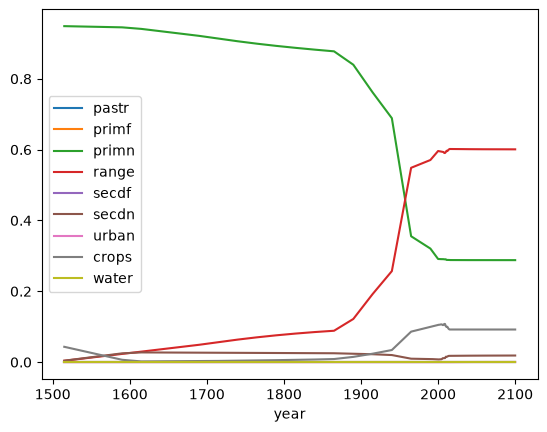

<Axes: xlabel='year'>

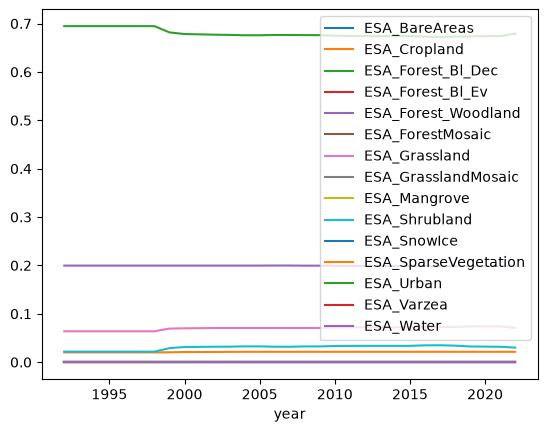

In [132]:
luh.query('cell == 12').set_index('year')[luh_cols].plot()
plt.show()
esa.query('cell == 12').set_index('year')[esa_cols].plot()

<Axes: xlabel='year'>

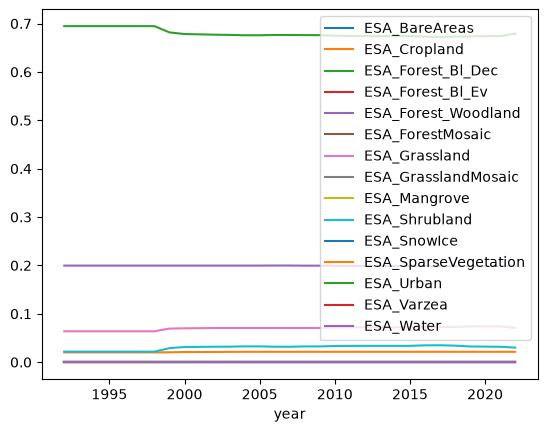

In [120]:
esa[esa_cols].sum(axis=1).describe().round(3)

count    251472.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
dtype: float64

In [109]:
common_years = sorted(list(set(luh['year']).intersection(set(esa['year']))))
common_years

[1992.0,
 1993.0,
 1994.0,
 1995.0,
 1996.0,
 1997.0,
 1998.0,
 1999.0,
 2000.0,
 2001.0,
 2002.0,
 2003.0,
 2004.0,
 2005.0,
 2006.0,
 2007.0,
 2008.0,
 2009.0,
 2010.0,
 2011.0,
 2012.0,
 2013.0,
 2014.0,
 2015.0,
 2016.0,
 2017.0,
 2018.0,
 2019.0,
 2020.0,
 2021.0,
 2022.0]

In [110]:
df = luh.merge(esa, how='inner', on=['year', 'cell'])
df

,cell,pastr,primf,primn,range,secdf,secdn,urban,crops,year,...,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water
0,11.0,0.0,0.0,0.312345,0.586137,0.0,0.003938,0.000000e+00,8.446474e-02,1992.0,...,0.000000,0.000245,0.000000,0.0,0.034974,0.0,0.000000,0.000000,0.0,0.000000
1,12.0,0.0,0.0,0.314751,0.575754,0.0,0.008655,3.219121e-20,1.008395e-01,1992.0,...,0.000000,0.063771,0.000000,0.0,0.021795,0.0,0.000000,0.000000,0.0,0.000000
2,13.0,0.0,0.0,0.343811,0.515906,0.0,0.024807,0.000000e+00,1.154758e-01,1992.0,...,0.000000,0.081749,0.000000,0.0,0.002361,0.0,0.000000,0.000000,0.0,0.000000
3,188.0,0.0,0.0,0.322310,0.406522,0.0,0.002457,0.000000e+00,2.687117e-01,1992.0,...,0.000000,0.010905,0.000000,0.0,0.045288,0.0,0.000000,0.000000,0.0,0.000000
4,189.0,0.0,0.0,0.334078,0.377746,0.0,0.004828,0.000000e+00,2.833477e-01,1992.0,...,0.000000,0.008111,0.000000,0.0,0.393563,0.0,0.000000,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251467,28012.0,0.0,0.0,0.000036,0.161137,0.0,0.054764,1.758130e-06,4.155039e-26,2022.0,...,0.002743,0.000000,0.000000,0.0,0.717140,0.0,0.050186,0.000000,0.0,0.229930
251468,28187.0,0.0,0.0,0.048448,0.574366,0.0,0.372561,1.305427e-05,0.000000e+00,2022.0,...,0.000000,0.001019,0.000000,0.0,0.780646,0.0,0.202280,0.000000,0.0,0.015715
251469,28188.0,0.0,0.0,0.037148,0.594286,0.0,0.356737,1.699097e-05,0.000000e+00,2022.0,...,0.000000,0.009044,0.000033,0.0,0.543705,0.0,0.410193,0.000924,0.0,0.019052
251470,28189.0,0.0,0.0,0.141505,0.440519,0.0,0.417952,2.357366e-05,0.000000e+00,2022.0,...,0.000000,0.000000,0.000000,0.0,0.786287,0.0,0.188454,0.000000,0.0,0.000000


In [103]:
luh.merge(biome_df, how='left', on='cell')

,cell,pastr,primf,primn,range,secdf,secdn,urban,crops,year,efg
0,11.0,0.0,0.0,0.966554,0.003804,0.0,0.000728,0.000000,1.579979e-02,1515.0,11.0
1,12.0,0.0,0.0,0.948607,0.003873,0.0,0.004138,0.000060,4.332117e-02,1515.0,11.0
2,13.0,0.0,0.0,0.902261,0.003825,0.0,0.010533,0.000000,8.338182e-02,1515.0,11.0
3,188.0,0.0,0.0,0.981843,0.002625,0.0,0.000887,0.000000,1.464528e-02,1515.0,16.0
4,189.0,0.0,0.0,0.977367,0.002444,0.0,0.001257,0.000000,1.893209e-02,1515.0,16.0
...,...,...,...,...,...,...,...,...,...,...,...
1054555,28012.0,0.0,0.0,0.000036,0.161113,0.0,0.054781,0.000008,6.103870e-08,2100.0,7.0
1054556,28187.0,0.0,0.0,0.048441,0.574294,0.0,0.372513,0.000140,1.361898e-09,2100.0,7.0
1054557,28188.0,0.0,0.0,0.037143,0.594211,0.0,0.356700,0.000133,1.466205e-09,2100.0,7.0
1054558,28189.0,0.0,0.0,0.141484,0.440491,0.0,0.417805,0.000219,1.284660e-06,2100.0,7.0


In [32]:
data = raster.read()
biomes = np.ma.masked_array(data, data == 255)
biomes

masked_array(
  data=[[[--, --, --, ..., --, --, --],
         [--, --, --, ..., --, --, --],
         [--, --, --, ..., --, --, --],
         ...,
         [--, --, --, ..., --, --, --],
         [--, --, --, ..., --, --, --],
         [--, --, --, ..., --, --, --]]],
  mask=[[[ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True],
         ...,
         [ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True],
         [ True,  True,  True, ...,  True,  True,  True]]],
  fill_value=np.uint64(999999),
  dtype=uint8)

In [37]:
(1 - biomes.mask).sum()

np.int64(8109)

In [ ]:
df = pd.read_excel(DATA_DIR / 'poc_data.xlsx')